# Individual Differences in Delay Discounting

## Question

How do estimated delay-discounting parameters vary across participants, and
how are those individual differences related to observed choice behavior and
out-of-sample model performance?

This notebook examines participant-level variation in:

- Discount rate (k)
- Choice sensitivity (β)
- Intertemporal choice behavior
- Cross-validated model performance

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

In [53]:
parameter_path = Path(
    "../data/processed/becker_2023_parameters.csv"
)

cv_path = Path(
    "../data/processed/cross_validation_results.csv"
)

parameter_df = pd.read_csv(parameter_path)
cv_df = pd.read_csv(cv_path)

print("Parameter participants:", len(parameter_df))
print("CV participants:", len(cv_df))

Parameter participants: 159
CV participants: 159


In [54]:
individual_df = parameter_df.merge(
    cv_df,
    on="subj_ident",
    how="inner",
    validate="one_to_one",
    suffixes=("_fit", "_cv")
)

print("Merged participants:", len(individual_df))

individual_df.head()

Merged participants: 159


,subj_ident,n_trials_fit,estimated_k,estimated_beta,log_likelihood,log_k,k_boundary,beta_boundary,any_boundary,accuracy,baseline_accuracy,accuracy_gain_fit,n_trials_cv,cv_model_accuracy,cv_baseline_accuracy,accuracy_gain_cv,cv_model_log_loss,cv_baseline_log_loss,log_loss_gain
0,007_0001,76,0.003555,0.105503,-51.188404,-2.449181,False,False,False,0.657895,0.552632,0.105263,76,0.644737,0.552632,0.092105,0.710840,0.697340,-0.013500
1,007_0002,42,0.001927,1.432148,-15.649467,-2.715035,False,False,False,0.738095,0.714286,0.023810,42,0.761905,0.714286,0.047619,0.414495,0.613462,0.198966
2,007_0003,52,0.000001,0.327886,-28.156820,-6.000000,True,False,True,0.923077,0.788462,0.134615,52,0.923077,0.788462,0.134615,0.607072,0.555691,-0.051381
3,007_0004,63,0.010377,1.391946,-23.773564,-1.983935,False,False,False,0.857143,0.666667,0.190476,63,0.841270,0.666667,0.174603,0.429251,0.660245,0.230994
4,007_0005,57,0.573844,0.620087,-27.962017,-0.241206,False,False,False,0.807018,0.631579,0.175439,57,0.789474,0.631579,0.157895,0.789286,0.681467,-0.107818


## Distribution of Individual Discount Rates

The hyperbolic discount parameter k can vary across several orders of
magnitude. To make participant-level differences easier to visualize,
the analysis examines both raw k values and log10-transformed k values.

Larger k values indicate steeper temporal discounting, meaning future
rewards lose subjective value more quickly.

In [55]:
individual_df["log_k"] = np.log10(
    individual_df["estimated_k"]
)

individual_df[
    ["estimated_k", "log_k"]
].describe()

,estimated_k,log_k
count,159.000000,159.000000
mean,0.056374,-2.520133
std,0.170329,1.411841
min,0.000001,-6.000000
25%,0.001105,-2.956755
50%,0.004588,-2.338408
75%,0.018187,-1.740234
max,1.000000,0.000000


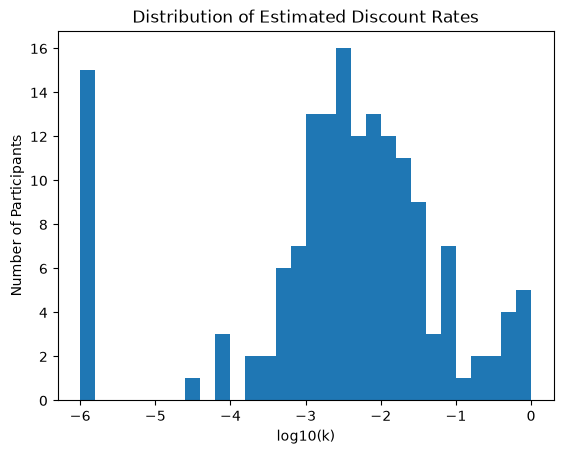

In [56]:
plt.hist(
    individual_df["log_k"],
    bins=30
)

plt.xlabel("log10(k)")
plt.ylabel("Number of Participants")
plt.title("Distribution of Estimated Discount Rates")

plt.show()

In [57]:
individual_df["log_beta"] = np.log10(
    individual_df["estimated_beta"]
)

individual_df[
    ["estimated_beta", "log_beta"]
].describe()

,estimated_beta,log_beta
count,159.000000,159.000000
mean,1.466784,-0.223707
std,2.216102,0.724359
min,0.001000,-3.000000
25%,0.398565,-0.399598
50%,0.788926,-0.102964
75%,1.371846,0.137305
max,10.000000,1.000000


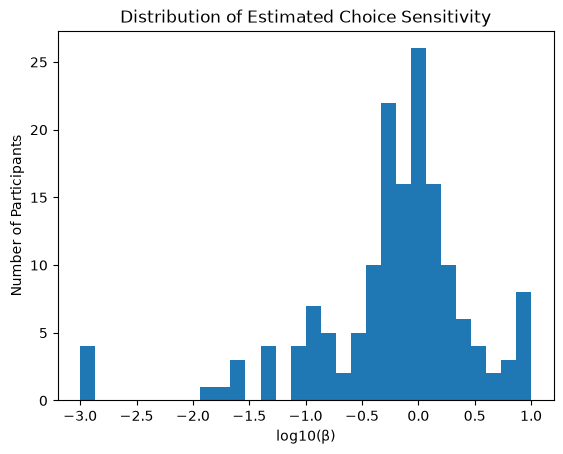

In [58]:
plt.hist(
    individual_df["log_beta"],
    bins=30
)

plt.xlabel("log10(β)")
plt.ylabel("Number of Participants")
plt.title("Distribution of Estimated Choice Sensitivity")

plt.show()

In [59]:
individual_df["k_boundary"] = (
    np.isclose(
        individual_df["estimated_k"],
        0.000001
    )
    |
    np.isclose(
        individual_df["estimated_k"],
        1.0
    )
)

individual_df["beta_boundary"] = (
    np.isclose(
        individual_df["estimated_beta"],
        0.001
    )
    |
    np.isclose(
        individual_df["estimated_beta"],
        10.0
    )
)

individual_df["any_boundary"] = (
    individual_df["k_boundary"]
    |
    individual_df["beta_boundary"]
)

individual_df[
    [
        "k_boundary",
        "beta_boundary",
        "any_boundary"
    ]
].sum()

k_boundary       17
beta_boundary    11
any_boundary     24
dtype: int64

In [60]:
interior_df = individual_df[
    ~individual_df["any_boundary"]
].copy()

print(
    "All participants:",
    len(individual_df)
)

print(
    "Interior estimates:",
    len(interior_df)
)

All participants: 159
Interior estimates: 135


In [61]:
file_path = Path("../data/raw/all_data.csv")

selected_paper = "Becker_2023_Exp1"

study_parts = []

for chunk in pd.read_csv(
    file_path,
    usecols=[
        "paper",
        "subj_ident",
        "choice",
        "subj_excl",
        "trial_excl"
    ],
    chunksize=100_000
):
    match = chunk[
        chunk["paper"] == selected_paper
    ]

    if not match.empty:
        study_parts.append(match)

study_df = pd.concat(
    study_parts,
    ignore_index=True
)

clean_df = study_df[
    (~study_df["subj_excl"]) &
    (~study_df["trial_excl"])
].copy()

print("Trials:", len(clean_df))
print(
    "Participants:",
    clean_df["subj_ident"].nunique()
)

Trials: 9898
Participants: 159


In [62]:
choice_summary = (
    clean_df
    .groupby("subj_ident")["choice"]
    .mean()
    .reset_index(name="ll_choice_rate")
)

choice_summary["immediate_choice_rate"] = (
    1 - choice_summary["ll_choice_rate"]
)

choice_summary.head()

,subj_ident,ll_choice_rate,immediate_choice_rate
0,007_0001,0.552632,0.447368
1,007_0002,0.714286,0.285714
2,007_0003,0.788462,0.211538
3,007_0004,0.666667,0.333333
4,007_0005,0.368421,0.631579


In [63]:
individual_df = individual_df.merge(
    choice_summary[
        [
            "subj_ident",
            "immediate_choice_rate"
        ]
    ],
    on="subj_ident",
    how="left",
    validate="one_to_one"
)

In [64]:
individual_df["log_k"] = np.log10(
    individual_df["estimated_k"]
)

interior_df = individual_df[
    ~individual_df["any_boundary"]
].copy()

print("Participants used:", len(interior_df))

Participants used: 135


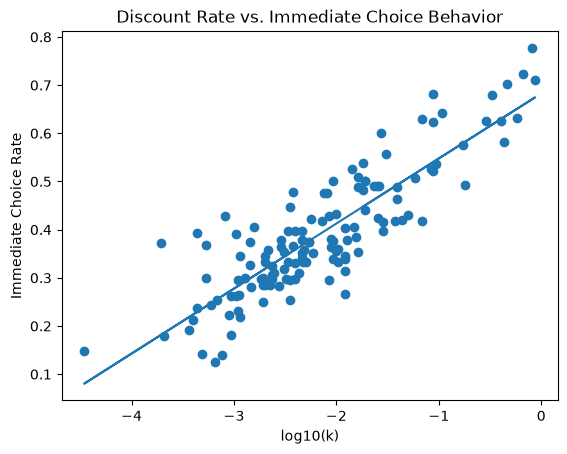

In [65]:
x = interior_df["log_k"]
y = interior_df["immediate_choice_rate"]

slope, intercept = np.polyfit(
    x,
    y,
    1
)

plt.scatter(x, y)

plt.plot(
    x,
    slope * x + intercept
)

plt.xlabel("log10(k)")
plt.ylabel("Immediate Choice Rate")
plt.title(
    "Discount Rate vs. Immediate Choice Behavior"
)

plt.show()

In [66]:
correlation = interior_df[
    "log_k"
].corr(
    interior_df["immediate_choice_rate"]
)

print(
    "Correlation between log10(k) "
    "and immediate choice rate:",
    correlation
)

Correlation between log10(k) and immediate choice rate: 0.863241734272177


In [67]:
predicted_y = slope * x + intercept

ss_res = np.sum(
    (y - predicted_y) ** 2
)

ss_tot = np.sum(
    (y - y.mean()) ** 2
)

r_squared = 1 - ss_res / ss_tot

print("R-squared:", r_squared)

R-squared: 0.7451862917892353


### Discount Rate and Immediate Choice Behavior

Estimated discount rates were strongly positively associated with observed
immediate-choice behavior among participants with non-boundary parameter
estimates (r = 0.863, R² = 0.745).

Participants with larger values of k tended to choose smaller-sooner rewards
more frequently, consistent with the theoretical interpretation of k as the
rate at which delayed rewards lose subjective value.

Because k was estimated from these same choice data, this relationship should
be interpreted as a consistency check on the fitted parameter rather than as
an independent test of predictive validity.

In [68]:
beta_accuracy_corr = interior_df[
    "log_beta"
].corr(
    interior_df["cv_model_accuracy"]
)

print(
    "Correlation between log10(beta) "
    "and CV model accuracy:",
    beta_accuracy_corr
)

Correlation between log10(beta) and CV model accuracy: 0.8369090512609823


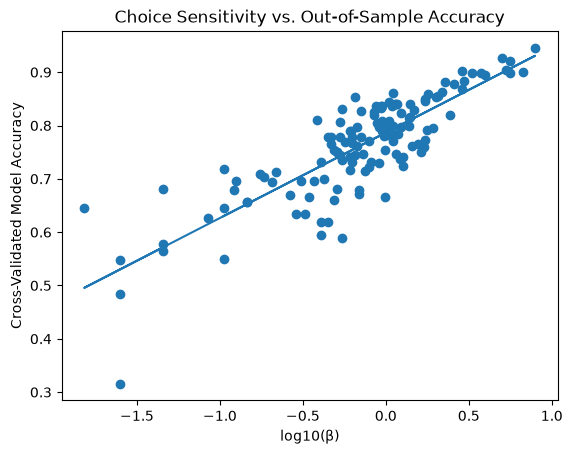

In [69]:
x = interior_df["log_beta"]
y = interior_df["cv_model_accuracy"]

slope, intercept = np.polyfit(
    x,
    y,
    1
)

plt.scatter(x, y)

plt.plot(
    x,
    slope * x + intercept
)

plt.xlabel("log10(β)")
plt.ylabel("Cross-Validated Model Accuracy")
plt.title(
    "Choice Sensitivity vs. Out-of-Sample Accuracy"
)

plt.show()

In [70]:
beta_logloss_corr = interior_df[
    "log_beta"
].corr(
    interior_df["log_loss_gain"]
)

print(
    "Correlation between log10(beta) "
    "and log-loss improvement:",
    beta_logloss_corr
)

Correlation between log10(beta) and log-loss improvement: 0.7189359872660589


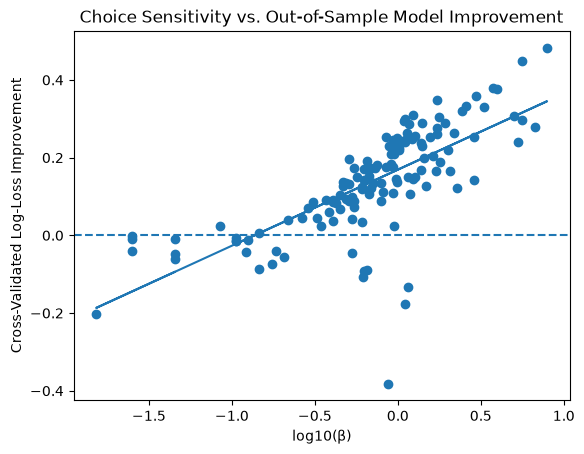

In [71]:
x = interior_df["log_beta"]
y = interior_df["log_loss_gain"]

slope, intercept = np.polyfit(
    x,
    y,
    1
)

plt.scatter(x, y)

plt.plot(
    x,
    slope * x + intercept
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("log10(β)")
plt.ylabel("Cross-Validated Log-Loss Improvement")
plt.title(
    "Choice Sensitivity vs. Out-of-Sample Model Improvement"
)

plt.show()

### Choice Sensitivity and Out-of-Sample Performance

Choice sensitivity was strongly associated with out-of-sample model
performance. Participants with larger estimated β values showed higher
cross-validated classification accuracy (r = 0.837) and greater
cross-validated log-loss improvement over the majority-choice baseline
(r = 0.719).

This pattern is consistent with the interpretation of β as a measure of
choice sensitivity. Larger β values indicate that choices are more strongly
determined by differences in subjective value, making behavior more
consistent and therefore easier for the delay-discounting model to predict.

Although model performance was evaluated on held-out trials, β was estimated
from each participant's full dataset in the individual-differences analysis.
These associations should therefore be interpreted descriptively rather than
as fully independent predictive tests of β.

In [72]:
parameter_corr = interior_df[
    "log_k"
].corr(
    interior_df["log_beta"]
)

print(
    "Correlation between log10(k) "
    "and log10(beta):",
    parameter_corr
)

Correlation between log10(k) and log10(beta): -0.3208393720542196


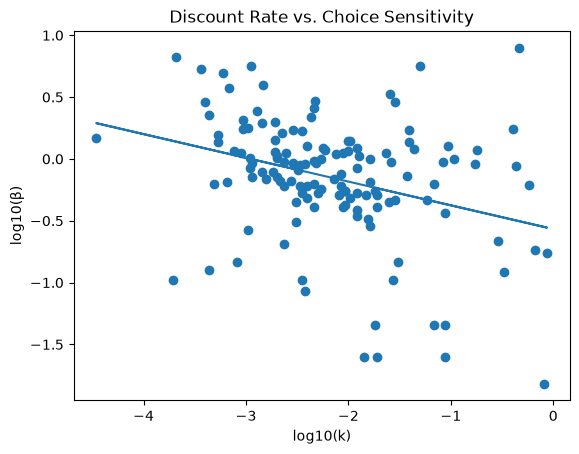

In [73]:
x = interior_df["log_k"]
y = interior_df["log_beta"]

slope, intercept = np.polyfit(
    x,
    y,
    1
)

plt.scatter(x, y)

plt.plot(
    x,
    slope * x + intercept
)

plt.xlabel("log10(k)")
plt.ylabel("log10(β)")
plt.title(
    "Discount Rate vs. Choice Sensitivity"
)

plt.show()

### Relationship Between Model Parameters

Discount rate and choice sensitivity showed a modest negative association.
Participants with larger estimated discount rates tended to have somewhat
smaller choice-sensitivity parameters, although substantial variability
remained.

This suggests that k and β capture related but distinct aspects of
intertemporal choice behavior. Because both parameters are jointly estimated
from the same choices, this association may partly reflect statistical
tradeoffs between parameter estimates and should not be interpreted as a
causal relationship.

In [74]:
individual_df["n_trials"] = individual_df["n_trials_fit"]

interior_df = individual_df[
    ~individual_df["any_boundary"]
].copy()

In [75]:
trials_k_corr = interior_df[
    "n_trials"
].corr(
    interior_df["log_k"],
    method="spearman"
)

trials_beta_corr = interior_df[
    "n_trials"
].corr(
    interior_df["log_beta"],
    method="spearman"
)

print(
    "Spearman correlation: trials vs log10(k):",
    trials_k_corr
)

print(
    "Spearman correlation: trials vs log10(beta):",
    trials_beta_corr
)

Spearman correlation: trials vs log10(k): -0.08730679224265302
Spearman correlation: trials vs log10(beta): -0.2181526382493961


In [76]:
trials_accuracy_corr = individual_df[
    "n_trials"
].corr(
    individual_df["cv_model_accuracy"],
    method="spearman"
)

trials_logloss_corr = individual_df[
    "n_trials"
].corr(
    individual_df["log_loss_gain"],
    method="spearman"
)

print(
    "Trials vs CV accuracy:",
    trials_accuracy_corr
)

print(
    "Trials vs log-loss improvement:",
    trials_logloss_corr
)

Trials vs CV accuracy: -0.20759513172445385
Trials vs log-loss improvement: 0.03706110059466749


In [77]:
individual_df.groupby(
    "any_boundary"
)["n_trials"].describe()

,count,mean,std,min,25%,50%,75%,max
any_boundary,,,,,,,,
False,135.0,64.02963,17.530332,30.0,53.00,59.0,70.0,134.0
True,24.0,52.25000,15.938059,31.0,45.75,50.0,53.5,112.0


In [78]:
from scipy.stats import mannwhitneyu

interior_trials = individual_df.loc[
    ~individual_df["any_boundary"],
    "n_trials"
]

boundary_trials = individual_df.loc[
    individual_df["any_boundary"],
    "n_trials"
]

u_stat, p_value = mannwhitneyu(
    interior_trials,
    boundary_trials,
    alternative="two-sided"
)

print("Mann-Whitney U:", u_stat)
print("p-value:", p_value)

Mann-Whitney U: 2424.0
p-value: 0.00010993410855143223


### Trial Count and Parameter Reliability

Trial count showed little relationship with the estimated discount rate
(ρ = -0.087), estimated choice sensitivity (ρ = -0.219), or cross-validated
log-loss improvement (ρ = 0.037). Its association with classification
accuracy was also weak (ρ = -0.208).

However, participants with boundary parameter estimates completed fewer trials.
Participants with interior estimates completed approximately 64 trials on
average (median = 59), compared with approximately 52 trials among participants
with at least one boundary estimate (median = 50).

A two-sided Mann–Whitney U test indicated that the trial-count distributions
differed between these groups (U = 2424, p < .001). This suggests that reduced
data quantity may contribute to difficulty identifying stable individual-level
model parameters.

## Conclusion

This notebook examined how individual differences in fitted delay-discounting
parameters relate to observed choice behavior, predictive performance, and
data quantity.

Estimated discount rate (`k`) was strongly associated with observed choice
behavior. Participants with larger discount rates chose the immediate option
more frequently (`r = 0.863`, `R² = 0.745`), consistent with the interpretation
of larger `k` as steeper discounting of delayed rewards.

Estimated choice sensitivity (`β`) was also strongly related to model
performance. Larger `β` values were associated with higher cross-validated
classification accuracy (`r = 0.837`) and greater cross-validated log-loss
improvement over the baseline (`r = 0.719`). This is consistent with `β`
capturing how consistently choices follow differences in subjective value.

The estimated `k` and `β` parameters showed a negative relationship, but with
substantial variation across participants. This suggests that the two
parameters capture related but distinct aspects of intertemporal choice:
`k` primarily reflects the tendency to discount delayed outcomes, whereas
`β` reflects the consistency or sensitivity of choice behavior.

Trial count was only weakly related to the estimated parameters and model
performance. Correlations with `log10(k)`, `log10(β)`, cross-validated accuracy,
and log-loss improvement were small (`ρ = -0.087`, `-0.219`, `-0.208`, and
`0.037`, respectively). However, participants with boundary parameter estimates
completed fewer trials on average than participants with interior estimates
(approximately 52 vs. 64 trials). This difference was statistically significant
in a two-sided Mann–Whitney U test (`U = 2424`, `p < .001`), suggesting that
lower data quantity may contribute to difficulty obtaining stable
individual-level parameter estimates.

Overall, the results support interpretable individual differences in both
discount rate and choice sensitivity while also highlighting an important
limitation of participant-level parameter estimation: reliable estimates
depend partly on having sufficient behavioral data.

Because these parameters and behavioral summaries are derived from the same
participants' choices, the relationships reported here should primarily be
interpreted as descriptive and model-consistency evidence rather than as
independent causal or predictive tests.